# Step 10 — Candidati stocastici con utilizzo vincolato

Stimiamo cinque kernel congiunti per utilizzo X e log priority fee p50 Y, senza usare il testing per scegliere specifiche.
Lo [step 11](../step11/dataset_ethereum.ipynb) confronta previsioni probabilistiche e una policy con kernel empirico.

### Metodo, supporto e fonti

Dataset Ethereum [Zenodo 22094893](https://doi.org/10.5281/zenodo.22094893), verificato nello step 1.
Tre finestre disgiunte di 30.000 blocchi, a inizio, centro e fine campione; ciascuna: 20.000 training, 5.000 validation, 5.000 testing.
Questo notebook stima soltanto sul training e verifica la generazione al suo confine; non seleziona il modello finale.

X = 2 gas_used / gas_limit è in [0,2], Y = log(1 + p50 in wei/gas) in [0,+∞).
Le censure X∈[0,2] e Y≥0 generano masse ai bordi: non applichiamo logit o epsilon alle osservazioni nulle.
Baseline, GARCH e regime usano innovazioni empiriche **coppiate**, di supporto finito; la miscela ha due componenti gaussiane congiunte.
Non imponiamo un cap superiore a Y. La Student-t sui log è soltanto diagnostica: exp(t) non ha media finita e non è il kernel risk-neutral.

La base fee del primo figlio è già determinata dal padre chiuso. Nei percorsi successivi manteniamo il gas limit del padre costante,
riconduciamo il gas simulato a interi e usiamo la funzione EIP-1559 esatta del progetto. Questa assunzione va rivalutata se cambia il gas limit.
Il kernel empirico condiziona solo su X e Y del padre, non sulla base fee: è un benchmark con uno stato esplicitamente ridotto.
Riferimento: [checklist, punto 10](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md).

## Risultati osservati

I 15 fit convergono, ma GARCH nel periodo centrale genera fino a **20,97 milioni di gwei/gas** nel controllo a cinque blocchi; la persistenza è **0,99698**.
La baseline censurata genera un atomo `X=2` nel **1,91–4,10%** dei passi, assente nei training. I regimi osservati e le componenti della miscela cambiano fra periodi: nessun candidato viene selezionato qui.
Dettagli e limiti in [findings.md](findings.md); confronto probabilistico e policy benchmark nello step 11.

## Dati, tre periodi e contratto condiviso

Fissiamo finestre, ruoli e unità prima di stimare i modelli.
Il modulo condiviso espone fit_candidate, sample_joint, filtered_variance e simulate_paths per lo step 11.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.diagnostic import het_arch

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file())
for path in [root, root / "src"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

## Import del kernel e verifica degli input

Riusiamo il modulo condiviso e la ricorrenza esatta del progetto, dopo aver individuato la radice.
Verifichiamo UUID, chain e continuità prima di definire i tre periodi.

In [2]:
from experiments.math_exp.stats_analysis.step10.transition_models import (
    CANDIDATES,
    REGIME_THRESHOLD,
    Y_COLUMN,
    filtered_variance,
    fit_candidate,
    sample_joint,
    simulate_paths,
)
from kairos.temporal import _forming_child_base_fee

source = root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((source / "preprocessing_summary.json").read_text())
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
df = pd.read_parquet(source / "ethereum_blocks_diagnostics.parquet")
assert len(df) == summary["rows"]
assert df.block_number.diff().iloc[1:].eq(1).all()
output = root / "outputs/notebook_diagnostics/ethereum/step10"
output.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {"figure.figsize": (10, 4), "font.size": 11, "axes.grid": True, "grid.alpha": 0.2}
)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
starts = {"inizio": 0, "centro": (len(df) - 30000) // 2, "fine": len(df) - 30000}
periods = {
    name: df.iloc[start : start + 30000].reset_index(drop=True) for name, start in starts.items()
}
assert starts["inizio"] + 30000 <= starts["centro"]
assert starts["centro"] + 30000 <= starts["fine"]
scopes = pd.DataFrame(
    [
        {
            "periodo": name,
            "primo_blocco": int(frame.block_number.iloc[0]),
            "ultimo_blocco": int(frame.block_number.iloc[-1]),
            "inizio_UTC": str(pd.to_datetime(frame.timestamp.iloc[0], unit="s", utc=True)),
            "fine_UTC": str(pd.to_datetime(frame.timestamp.iloc[-1], unit="s", utc=True)),
            "X_zero_training": int(frame.X.iloc[:20000].eq(0).sum()),
            "fee_zero_training": int(frame[Y_COLUMN].iloc[:20000].eq(0).sum()),
        }
        for name, frame in periods.items()
    ]
)
display(scopes)
scopes.to_csv(output / "periods.csv", index=False)
models, timings = {}, []


def fit_all(name):
    for period, frame in periods.items():
        start = time.perf_counter()
        models[period, name] = fit_candidate(frame.iloc[:20000], name)
        timings.append(
            {"periodo": period, "candidato": name, "secondi": time.perf_counter() - start}
        )


def coefficients_table(name):
    return pd.DataFrame(
        [
            {
                "periodo": period,
                "target": target,
                "intercetta": model.coefficients[j, 0],
                "AR1": model.coefficients[j, 1],
            }
            for (period, candidate), model in models.items()
            if candidate == name
            for j, target in enumerate(["X", "log_p50"])
        ]
    )

,periodo,primo_blocco,ultimo_blocco,inizio_UTC,fine_UTC,X_zero_training,fee_zero_training
0,inizio,23935694,23965693,2025-12-03 21:49:23+00:00,2025-12-08 04:25:23+00:00,3,176
1,centro,24747962,24777961,2026-03-27 09:20:23+00:00,2026-03-31 13:42:47+00:00,9,183
2,fine,25560230,25590229,2026-07-18 14:37:23+00:00,2026-07-22 19:02:47+00:00,4,96


## 1.1 — Baseline: autoregressione con utilizzo vincolato

Stimiamo AR(1) per X con innovazioni empiriche coppiate a quelle delle fee.
La censura nel kernel conserva il supporto fisico e ammette masse a X=0 e X=2.

In [3]:
fit_all("baseline")
baseline_coefficients = coefficients_table("baseline")
display(baseline_coefficients.query("target == 'X'"))
baseline_coefficients.to_csv(output / "baseline_coefficients.csv", index=False)
for period, frame in periods.items():
    parent = frame.iloc[19999]
    draws, _ = sample_joint(
        models[period, "baseline"], parent.X, parent[Y_COLUMN], 2000, np.random.default_rng(100)
    )
    assert np.isfinite(draws).all() and ((draws[:, 0] >= 0) & (draws[:, 0] <= 2)).all()
    print(period, "masse simulate X=0 / X=2:", np.mean(draws[:, 0] == 0), np.mean(draws[:, 0] == 2))

,periodo,target,intercetta,AR1
0,inizio,X,1.224610,-0.204369
2,centro,X,1.232335,-0.213802
4,fine,X,1.212650,-0.195496


inizio masse simulate X=0 / X=2: 0.0095 0.013
centro masse simulate X=0 / X=2: 0.001 0.055
fine masse simulate X=0 / X=2: 0.0025 0.0145


## 1.2 — Baseline: AR(1) delle log priority fee

Esaminiamo intercetta, persistenza e innovazioni del processo Y senza eliminare le fee nulle.
Y viene censurata soltanto inferiormente a zero; nessun massimo del training diventa un cap artificiale.

In [4]:
display(baseline_coefficients.query("target == 'log_p50'"))
innovation_rows = []
for period in periods:
    model = models[period, "baseline"]
    for j, target in enumerate(["X", "log_p50"]):
        innovation_rows.append(
            {
                "periodo": period,
                "target": target,
                "std_innovazioni": model.innovations[:, j].std(),
                "skewness": stats.skew(model.innovations[:, j]),
                "kurtosi_eccesso": stats.kurtosis(model.innovations[:, j]),
            }
        )
innovation_report = pd.DataFrame(innovation_rows)
display(innovation_report)
innovation_report.to_csv(output / "baseline_innovations.csv", index=False)

,periodo,target,intercetta,AR1
1,inizio,log_p50,12.763874,0.140712
3,centro,log_p50,11.493752,0.139802
5,fine,log_p50,13.056341,0.163897


,periodo,target,std_innovazioni,skewness,kurtosi_eccesso
0,inizio,X,0.512919,0.363516,-0.656926
1,inizio,log_p50,3.587371,-1.884511,5.511338
2,centro,X,0.485520,0.265767,-0.611735
3,centro,log_p50,5.234702,-1.125137,0.234292
4,fine,X,0.470508,0.344937,-0.507967
5,fine,log_p50,2.189544,-1.969683,13.062898


## 1.3 — Baseline: ricorrenza deterministica EIP-1559

Ricostruiamo la base fee del primo blocco validation dal padre training chiuso.
La confrontiamo con quella osservata, usando interi e la funzione già presente nel progetto.

In [5]:
protocol_rows = []
for period, frame in periods.items():
    parent, child = frame.iloc[19999], frame.iloc[20000]
    expected = _forming_child_base_fee(
        int(parent.base_fee_per_gas), int(parent.gas_used), int(parent.gas_limit)
    )
    protocol_rows.append(
        {
            "periodo": period,
            "blocco_figlio": int(child.block_number),
            "base_fee_attesa_wei": expected,
            "base_fee_osservata_wei": int(child.base_fee_per_gas),
        }
    )
    assert expected == int(child.base_fee_per_gas)
protocol_report = pd.DataFrame(protocol_rows)
display(protocol_report)
protocol_report.to_csv(output / "base_fee_boundary_check.csv", index=False)

,periodo,blocco_figlio,base_fee_attesa_wei,base_fee_osservata_wei
0,inizio,23955694,26872225,26872225
1,centro,24767962,132691678,132691678
2,fine,25580230,173682227,173682227


## 2.1 — Volatilità: stessa autoregressione vincolata per X

Aggiungiamo GARCH alle fee mantenendo il medesimo modello bounded per l'utilizzo.
I coefficienti della media restano confrontabili con la baseline sullo stesso training.

In [6]:
fit_all("garch")
display(coefficients_table("garch").query("target == 'X'"))
for period in periods:
    assert np.array_equal(
        models[period, "baseline"].coefficients, models[period, "garch"].coefficients
    )

,periodo,target,intercetta,AR1
0,inizio,X,1.224610,-0.204369
2,centro,X,1.232335,-0.213802
4,fine,X,1.212650,-0.195496


## 2.2 — AR-GARCH delle log priority fee

Stimiamo GARCH(1,1) sulle innovazioni AR delle fee e ne verifichiamo persistenza e residui standardizzati.
La likelihood gaussiana serve alla stima della varianza; il kernel generativo usa coppie empiriche finite.

In [7]:
garch_rows = []
for period in periods:
    model = models[period, "garch"]
    omega, alpha, beta = model.garch_parameters
    garch_rows.append(
        {
            "periodo": period,
            "omega": omega,
            "alpha": alpha,
            "beta": beta,
            "persistenza": alpha + beta,
            "h_prossimo": model.next_variance,
            "ARCH10_p_standardizzati": het_arch(model.innovations[:, 1], nlags=10)[1],
        }
    )
garch_report = pd.DataFrame(garch_rows)
display(garch_report)
garch_report.to_csv(output / "garch_parameters.csv", index=False)
# Nessuna osservazione validation: il filtro deve restituire esattamente lo stato di fine training.
for period, frame in periods.items():
    assert (
        filtered_variance(models[period, "garch"], frame.iloc[20000:20000])
        == models[period, "garch"].next_variance
    )

/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,periodo,omega,alpha,beta,persistenza,h_prossimo,ARCH10_p_standardizzati
0,inizio,0.164927,0.057084,0.931487,0.988571,6.489024,0.045821
1,centro,0.084016,0.037678,0.959297,0.996976,33.910237,0.050998
2,fine,0.254723,0.101862,0.855390,0.957252,5.207960,0.446017


## 2.3 — Volatilità: base fee deterministica invariata

Simuliamo cinque blocchi con AR-GARCH e controlliamo che la prima base fee sia già nota dal padre.
Solo utilizzo e fee successive sono stocastici; il gas limit è mantenuto costante nell'orizzonte.

In [8]:
paths = {}
for period, frame in periods.items():
    parent = frame.iloc[19999]
    paths[period, "garch"] = simulate_paths(
        models[period, "garch"], parent, 5, 512, np.random.default_rng(101)
    )
    expected = _forming_child_base_fee(
        int(parent.base_fee_per_gas), int(parent.gas_used), int(parent.gas_limit)
    )
    assert np.all(paths[period, "garch"]["B"][:, 0] == expected)
print("Ricorrenza esatta e primo figlio deterministico verificati nei tre periodi.")

Ricorrenza esatta e primo figlio deterministico verificati nei tre periodi.


## 3.1 — Markov switching dell'utilizzo: regimi osservati

Definiamo due regimi osservabili del gas, X<1,5 e X≥1,5, e stimiamo una catena di Markov.
Le transizioni stimate guidano il regime del prossimo draw; non presentiamo questo modello come HMM latente.

In [9]:
fit_all("regime")
regime_coefficient_rows = []
for period in periods:
    model = models[period, "regime"]
    for state in range(2):
        for j, target in enumerate(["X", "log_p50"]):
            regime_coefficient_rows.append(
                {
                    "periodo": period,
                    "regime_padre": state,
                    "target": target,
                    "intercetta": model.regime_coefficients[state, j, 0],
                    "AR1": model.regime_coefficients[state, j, 1],
                }
            )
regime_coefficients = pd.DataFrame(regime_coefficient_rows)
display(regime_coefficients.query("target == 'X'"))
regime_coefficients.to_csv(output / "regime_coefficients.csv", index=False)

,periodo,regime_padre,target,intercetta,AR1
0,inizio,0,X,1.407204,-0.464719
2,inizio,1,X,0.463024,0.262497
4,centro,0,X,1.363726,-0.395734
6,centro,1,X,0.392502,0.298950
8,fine,0,X,1.349901,-0.381280
10,fine,1,X,0.842215,0.058507


## 3.2 — Dinamiche delle fee dipendenti dal regime

Confrontiamo le autoregressioni delle log fee stimate separatamente nei due regimi del padre.
Il regime è osservato al momento della decisione e non ricostruito con probabilità smoothed future.

In [10]:
display(regime_coefficients.query("target == 'log_p50'"))
print(
    "I residui sono campionati dalla stessa transizione di regime per X e Y: "
    "nessuna indipendenza imposta."
)

,periodo,regime_padre,target,intercetta,AR1
1,inizio,0,log_p50,13.428195,0.099033
3,inizio,1,log_p50,11.535549,0.229764
5,centro,0,log_p50,11.557422,0.133493
7,centro,1,log_p50,11.229724,0.172118
9,fine,0,log_p50,13.044952,0.162754
11,fine,1,log_p50,12.293474,0.226084


I residui sono campionati dalla stessa transizione di regime per X e Y: nessuna indipendenza imposta.


## 3.3 — Volatilità dipendente dal regime

Confrontiamo la dispersione delle coppie di innovazioni nelle quattro transizioni fra regimi.
Queste varianze condizionate sono osservate nel training e non identificano da sole uno stato latente.

In [11]:
regime_volatility_rows = []
for period in periods:
    for (old, new), pool in models[period, "regime"].regime_pools.items():
        regime_volatility_rows.append(
            {
                "periodo": period,
                "regime_padre": old,
                "regime_figlio": new,
                "N": len(pool),
                "std_X": pool[:, 0].std(),
                "std_log_p50": pool[:, 1].std(),
                "correlazione": np.corrcoef(pool.T)[0, 1],
            }
        )
regime_volatility = pd.DataFrame(regime_volatility_rows)
display(regime_volatility)
regime_volatility.to_csv(output / "regime_volatility.csv", index=False)

,periodo,regime_padre,regime_figlio,N,std_X,std_log_p50,correlazione
0,inizio,0,0,12401,0.358072,3.182968,-0.265757
1,inizio,0,1,3435,0.206694,3.658969,-0.096639
2,inizio,1,0,3435,0.334404,3.582949,-0.317275
3,inizio,1,1,728,0.164694,4.787763,0.032691
4,centro,0,0,12809,0.360482,4.990480,-0.366220
5,centro,0,1,3310,0.193786,5.257821,0.022255
6,centro,1,0,3310,0.344066,5.251921,-0.495708
7,centro,1,1,570,0.159662,5.751677,-0.029175
8,fine,0,0,13370,0.344880,2.151587,-0.190067
9,fine,0,1,3071,0.191193,1.829534,-0.017898


## 3.4 — Probabilità di transizione e controllo del generatore

Esponiamo la matrice di transizione con prior esplicita di mezzo conteggio per cella.
Verifichiamo che la quota di draw nel regime alto sia coerente con la probabilità stimata.

In [12]:
transition_rows = []
for period in periods:
    model = models[period, "regime"]
    for state in range(2):
        draws, _ = sample_joint(
            model, 0.75 if state == 0 else 1.75, 20.0, 10000, np.random.default_rng(102 + state)
        )
        high = np.mean(draws[:, 0] >= REGIME_THRESHOLD)
        assert abs(high - model.transitions[state, 1]) < 0.03
        transition_rows.append(
            {
                "periodo": period,
                "regime_padre": state,
                "P_basso": model.transitions[state, 0],
                "P_alto": model.transitions[state, 1],
                "quota_alta_simulata": high,
            }
        )
transition_report = pd.DataFrame(transition_rows)
display(transition_report)
transition_report.to_csv(output / "regime_transitions.csv", index=False)

,periodo,regime_padre,P_basso,P_alto,quota_alta_simulata
0,inizio,0,0.783071,0.216929,0.2198
1,inizio,1,0.825048,0.174952,0.1751
2,centro,0,0.794634,0.205366,0.2082
3,centro,1,0.853002,0.146998,0.1500
4,fine,0,0.813192,0.186808,0.1903
5,fine,1,0.863023,0.136977,0.1414


## 4.1 — Innovazioni con code ampie e limite della Student-t

Stimiamo Student-t sulle innovazioni come controllo della forma, senza usarla per generare le fee.
Su una variabile log t, exp(Y) non ha media finita: il kernel risk-neutral richiede un'altra distribuzione.

In [13]:
tail_rows = []
for period in periods:
    errors = models[period, "baseline"].innovations[:, 1]
    degrees, location, scale = stats.t.fit(errors)
    tail_rows.append(
        {
            "periodo": period,
            "t_gradi_liberta": degrees,
            "t_posizione": location,
            "t_scala": scale,
            "q99_abs_empirico": np.quantile(np.abs(errors), 0.99),
        }
    )
tail_report = pd.DataFrame(tail_rows)
display(tail_report)
tail_report.to_csv(output / "student_t_diagnostic.csv", index=False)
print(
    "Student-t sui log rifiutata come kernel generativo; empiriche finite e "
    "miscela gaussiana hanno momenti adeguati."
)

,periodo,t_gradi_liberta,t_posizione,t_scala,q99_abs_empirico
0,inizio,2.491912,0.454998,1.937960,14.271765
1,centro,1.291575,1.883122,1.977831,12.829662
2,fine,3.738702,0.109436,1.450550,5.874287


Student-t sui log rifiutata come kernel generativo; empiriche finite e miscela gaussiana hanno momenti adeguati.


## 4.2 — Miscela gaussiana congiunta a due componenti

Stimiamo realmente una miscela bivariata delle innovazioni X/Y con covarianza piena per componente.
Convergenza, pesi e scale mostrano se una componente più dispersa cattura gli shock senza imporre exp(t).

In [14]:
fit_all("mixture")
mixture_rows = []
for period in periods:
    model = models[period, "mixture"]
    weights, means, covariances = model.mixture
    assert model.diagnostics["mixture_converged"]
    for component in range(2):
        mixture_rows.append(
            {
                "periodo": period,
                "componente": component,
                "peso": weights[component],
                "media_X": means[component, 0],
                "media_log_p50": means[component, 1],
                "std_X": np.sqrt(covariances[component, 0, 0]),
                "std_log_p50": np.sqrt(covariances[component, 1, 1]),
                "iterazioni": model.diagnostics["mixture_iterations"],
            }
        )
mixture_report = pd.DataFrame(mixture_rows)
display(mixture_report)
mixture_report.to_csv(output / "mixture_parameters.csv", index=False)

,periodo,componente,peso,media_X,media_log_p50,std_X,std_log_p50,iterazioni
0,inizio,0,0.948063,-0.015883,0.646562,0.504788,2.259532,54
1,inizio,1,0.051937,0.289923,-11.802438,0.570500,2.767884,54
2,centro,0,0.808532,-0.058975,2.331070,0.477225,2.160890,14
3,centro,1,0.191468,0.249039,-9.843668,0.439030,1.885148,14
4,fine,0,0.966301,0.000009,0.124414,0.465678,1.744831,40
5,fine,1,0.033699,-0.000267,-3.567524,0.592463,6.464839,40


## 4.3 — Componente di salto: verifica del supporto empirico

Rileggiamo clustering e sensibilità GPD dello step 7 prima di aggiungere un processo di salto.
Non normalità e coppie picco-rientro non identificano salti: motiviamo la decisione senza simulare un Poisson non stimato.

**Ambito delle evidenze:** il clustering dello step 7 usa tutto il dataset, inclusi validation/testing; la GPD usa soltanto il training dell’ultimo periodo di luglio. Sono contesto esplorativo, non un criterio di selezione training-only per dicembre e marzo. La griglia dei cinque candidati è fissata in tutti i periodi: non si conclude che i salti siano assenti nei singoli training.

In [15]:
previous_findings = output.parent / "step7"
clustering = pd.read_csv(previous_findings / "extreme_clustering.csv")
gpd = pd.read_csv(previous_findings / "gpd_threshold_sensitivity.csv")
display(clustering[["variabile", "rapporto_vs_indipendenza"]])
display(gpd[gpd.variabile.eq("residual_log_p50")][["quantile", "cluster", "xi"]])
print(
    "Decisione: nessun processo di salto separato stimato; mancano "
    "identificazione e soglia stabile."
)
print(
    "Le code sono rappresentate da innovazioni empiriche o miscela gaussiana; il"
    " confronto fuori campione è nello step 11."
)

,variabile,rapporto_vs_indipendenza
0,delta_X,10.775595
1,delta_log_p50,32.635005
2,delta_log_p90,38.829612


,quantile,cluster,xi
3,0.950,619,0.793827
4,0.975,357,0.838136
5,0.990,144,-1.316967


Decisione: nessun processo di salto separato stimato; mancano identificazione e soglia stabile.
Le code sono rappresentate da innovazioni empiriche o miscela gaussiana; il confronto fuori campione è nello step 11.


## 4.4 — Preservare la dipendenza fra utilizzo e fee

Confrontiamo la dipendenza congiunta prodotta dai candidati sulla medesima origine di training.
Le innovazioni si campionano in coppia o con covarianza bivariata; non sommiamo due processi simulati indipendentemente.

In [16]:
dependence_rows = []
for period, frame in periods.items():
    parent = frame.iloc[19999]
    for name in ["baseline", "garch", "regime", "mixture"]:
        draws, _ = sample_joint(
            models[period, name], parent.X, parent[Y_COLUMN], 4000, np.random.default_rng(103)
        )
        dependence_rows.append(
            {
                "periodo": period,
                "candidato": name,
                "correlazione_X_Y_draw": np.corrcoef(draws.T)[0, 1],
            }
        )
dependence_report = pd.DataFrame(dependence_rows)
display(dependence_report)
dependence_report.to_csv(output / "joint_dependence.csv", index=False)

,periodo,candidato,correlazione_X_Y_draw
0,inizio,baseline,-0.401066
1,inizio,garch,-0.413482
2,inizio,regime,-0.357041
3,inizio,mixture,-0.381439
4,centro,baseline,-0.389098
5,centro,garch,-0.397193
6,centro,regime,-0.342827
7,centro,mixture,-0.381932
8,fine,baseline,-0.285495
9,fine,garch,-0.316453


## Alternativa 1 — Beta sull'utilizzo normalizzato

Valutiamo l'applicabilità della Beta su U=X/2, senza spostare artificialmente gli zeri.
La Beta continua ordinaria non assegna massa a U=0 o U=1 e non è adottata per questo campione.

In [17]:
beta_rows = []
for period, frame in periods.items():
    u = frame.X.iloc[:20000] / 2
    beta_rows.append(
        {
            "periodo": period,
            "zeri_U": int(u.eq(0).sum()),
            "uni_U": int(u.eq(1).sum()),
            "interni_U": int(u.between(0, 1, inclusive="neither").sum()),
        }
    )
beta_report = pd.DataFrame(beta_rows)
display(beta_report)
beta_report.to_csv(output / "beta_applicability.csv", index=False)
print(
    "Decisione: Beta ordinaria non rappresenta gli atomi; nessun logit con epsilon viene applicato."
)

,periodo,zeri_U,uni_U,interni_U
0,inizio,3,0,19997
1,centro,9,0,19991
2,fine,4,0,19996


Decisione: Beta ordinaria non rappresenta gli atomi; nessun logit con epsilon viene applicato.


## Alternativa 2 — Beta con inflazione agli estremi

Quantifichiamo gli atomi che richiederebbero una componente discreta insieme alla Beta continua.
Preferiamo il kernel empirico congiunto: conserva direttamente gli zeri e la dipendenza con le fee.

In [18]:
atom_report = beta_report.copy()
atom_report["massa_zero_training"] = atom_report.zeri_U / 20000
atom_report["massa_uno_training"] = atom_report.uni_U / 20000
display(atom_report[["periodo", "massa_zero_training", "massa_uno_training"]])
print(
    "Zero/one-inflated Beta considerata ma non stimata: richiederebbe anche un "
    "modello della dipendenza con Y."
)
print(
    "Gli atomi sono invece presenti nelle censure dei kernel AR e nelle "
    "transizioni reali del kernel empirico."
)

,periodo,massa_zero_training,massa_uno_training
0,inizio,0.00015,0.0
1,centro,0.00045,0.0
2,fine,0.00020,0.0


Zero/one-inflated Beta considerata ma non stimata: richiederebbe anche un modello della dipendenza con Y.
Gli atomi sono invece presenti nelle censure dei kernel AR e nelle transizioni reali del kernel empirico.


## Alternativa 3 — Catena di Markov discretizzata

Stimiamo il quinto candidato su celle congiunte X/Y del padre, con soglie X fisse e quantili Y del solo training.
Le transizioni fra celle formano una catena osservata e offrono un benchmark finito per la policy.

In [19]:
fit_all("empirical")
empirical_rows = []
for period, frame in periods.items():
    model = models[period, "empirical"]
    previous = frame[["X", Y_COLUMN]].iloc[:19999].to_numpy()
    current = frame[["X", Y_COLUMN]].iloc[1:20000].to_numpy()
    old = np.digitize(previous[:, 0], model.x_edges) * (len(model.y_edges) + 1) + np.digitize(
        previous[:, 1], model.y_edges
    )
    new = np.digitize(current[:, 0], model.x_edges) * (len(model.y_edges) + 1) + np.digitize(
        current[:, 1], model.y_edges
    )
    matrix = pd.crosstab(old, new, normalize="index")
    assert np.allclose(matrix.sum(axis=1), 1)
    matrix.to_csv(output / f"empirical_transition_{period}.csv")
    empirical_rows.append(
        {
            "periodo": period,
            "celle_occupate": len(model.conditional_pools),
            "cella_min_N": min(len(pool) for pool in model.conditional_pools.values()),
            "soglie_Y_training": model.y_edges.tolist(),
        }
    )
empirical_report = pd.DataFrame(empirical_rows)
display(empirical_report)
empirical_report.to_csv(output / "empirical_cells.csv", index=False)

,periodo,celle_occupate,cella_min_N,soglie_Y_training
0,inizio,20,83,"[13.815512, 15.155299, 16.850229]"
1,centro,20,109,"[13.815512, 14.914123, 16.534043]"
2,fine,20,126,"[14.739597, 15.501122, 16.856022]"


## Alternativa 4 — Distribuzione empirica condizionata congiunta

Campioniamo transizioni reali dalla cella del padre, mantenendo insieme utilizzo e log fee del figlio.
Le celle mai osservate ricadono esplicitamente sul pool globale training; B non è un regressore di questo benchmark.

In [20]:
empirical_check_rows = []
for period, frame in periods.items():
    parent = frame.iloc[19999]
    model = models[period, "empirical"]
    draws, _ = sample_joint(model, parent.X, parent[Y_COLUMN], 4000, np.random.default_rng(104))
    assert draws[:, 1].max() <= frame[Y_COLUMN].iloc[:20000].max()
    empirical_check_rows.append(
        {
            "periodo": period,
            "correlazione_X_Y": np.corrcoef(draws.T)[0, 1],
            "quota_X_zero": np.mean(draws[:, 0] == 0),
            "quota_Y_zero": np.mean(draws[:, 1] == 0),
        }
    )
display(pd.DataFrame(empirical_check_rows))
print(
    "Supporto finito e joint; limiti: nuove fee oltre il massimo training e "
    "dipendenza da B non sono rappresentate."
)

,periodo,correlazione_X_Y,quota_X_zero,quota_Y_zero
0,inizio,-0.476286,0.0,0.00850
1,centro,-0.240748,0.0,0.01375
2,fine,-0.133158,0.0,0.01350


Supporto finito e joint; limiti: nuove fee oltre il massimo training e dipendenza da B non sono rappresentate.


## Percorsi, plausibilità e artefatti riproducibili

Generiamo percorsi comuni a cinque blocchi da ciascun candidato e ne controlliamo supporto e scale.
I risultati servono al confronto dello step 11; nessun ranking in-sample viene chiamato modello selezionato.

,periodo,candidato,quota_X_zero,quota_X_due,quota_Y_zero,max_Y,max_P_gwei,quota_Y_oltre_max_training
0,inizio,baseline,0.011719,0.041016,0.010547,23.602027,1.779221e+01,0.000000
1,inizio,garch,0.011719,0.041016,0.001172,21.905365,3.261214e+00,0.000000
2,inizio,regime,0.018750,0.033984,0.007422,24.423129,4.044178e+01,0.000000
3,inizio,mixture,0.023828,0.029687,0.008203,22.690639,7.151863e+00,0.000000
4,inizio,empirical,0.000000,0.000000,0.013281,24.141115,3.050373e+01,0.000000
5,centro,baseline,0.007031,0.029297,0.005078,26.388176,2.885620e+02,0.000000
6,centro,garch,0.007031,0.029297,0.019141,37.581948,2.097166e+07,0.004297
7,centro,regime,0.007812,0.027344,0.004687,25.774268,1.561788e+02,0.000000
8,centro,mixture,0.018750,0.028516,0.007812,23.033173,1.007349e+01,0.000000
9,centro,empirical,0.001172,0.000000,0.010937,27.240462,6.766786e+02,0.000000


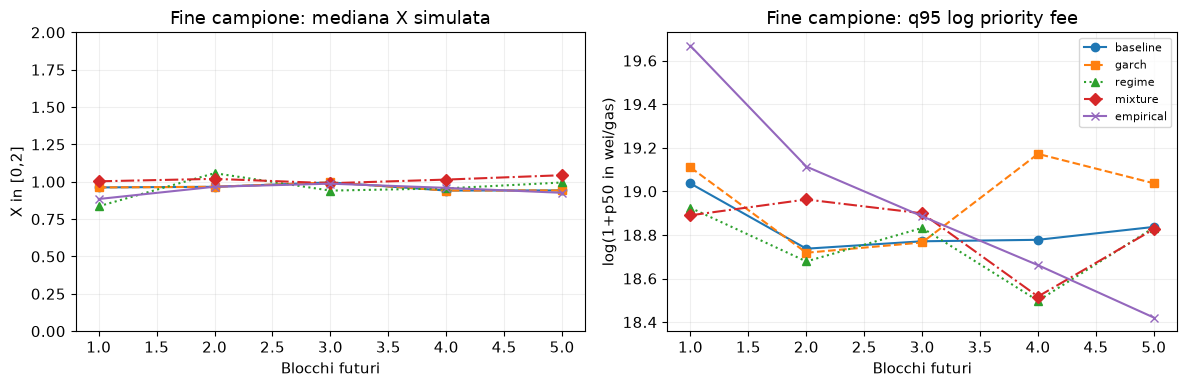

Modelli stimati:15; selezione probabilistica e misura testing delegate allo step11.


In [21]:
path_rows = []
for period, frame in periods.items():
    parent = frame.iloc[19999]
    for name in CANDIDATES:
        generated = simulate_paths(models[period, name], parent, 5, 512, np.random.default_rng(105))
        paths[period, name] = generated
        assert np.isfinite(np.concatenate(list(generated.values()))).all()
        assert (
            (generated["X"] >= 0).all()
            and (generated["X"] <= 2).all()
            and (generated["P"] >= 0).all()
        )
        path_rows.append(
            {
                "periodo": period,
                "candidato": name,
                "quota_X_zero": np.mean(generated["X"] == 0),
                "quota_X_due": np.mean(generated["X"] == 2),
                "quota_Y_zero": np.mean(generated["Y"] == 0),
                "max_Y": generated["Y"].max(),
                "max_P_gwei": generated["P"].max() / 1e9,
                "quota_Y_oltre_max_training": np.mean(
                    generated["Y"] > models[period, name].diagnostics["training_max_y"]
                ),
            }
        )
path_report = pd.DataFrame(path_rows)
display(path_report)
path_report.to_csv(output / "path_plausibility.csv", index=False)
pd.DataFrame(timings).to_csv(output / "fit_timings.csv", index=False)
(output / "analysis_scope.json").write_text(
    json.dumps(
        {
            "dataset_id": summary["dataset_id"],
            "dataset_sha256": summary["dataset_sha256"],
            "starts": starts,
            "training_rows": 20000,
            "validation_rows": 5000,
            "testing_rows": 5000,
            "candidates": list(CANDIDATES),
            "future_gas_limit": "held constant at closed parent",
            "fee_unit": "wei/gas",
            "Y_definition": "log1p(p50_wei)",
            "regime_type": "observed X threshold1.5",
        },
        indent=2,
    )
    + "\n"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, style in zip(CANDIDATES, ["-o", "--s", ":^", "-.D", "-x"], strict=True):
    values = paths["fine", name]
    axes[0].plot(np.arange(1, 6), np.median(values["X"], axis=0), style, label=name)
    axes[1].plot(np.arange(1, 6), np.quantile(values["Y"], 0.95, axis=0), style, label=name)
axes[0].set(
    title="Fine campione: mediana X simulata",
    xlabel="Blocchi futuri",
    ylabel="X in [0,2]",
    ylim=(0, 2),
)
axes[1].set(
    title="Fine campione: q95 log priority fee",
    xlabel="Blocchi futuri",
    ylabel="log(1+p50 in wei/gas)",
)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)
print("Modelli stimati:15; selezione probabilistica e misura testing delegate allo step11.")